<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Gradient_Boosting_Breast_Cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================
# GRADIENT BOOSTING - BREAST CANCER
# Laboratorio de Códigos
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Cargar dataset
data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = data.target

# En este dataset:
# 0 = Maligno
# 1 = Benigno

print("DIMENSIONES DEL DATASET")
print("-----------------------")
print("Registros:", X.shape[0])
print("Características:", X.shape[1])

print("\nCLASES")
print("0 =", data.target_names[0])
print("1 =", data.target_names[1])

print("\nPRIMEROS REGISTROS")
display(X.head())

print("\nDISTRIBUCIÓN DE CLASES")
print(pd.Series(y).value_counts())

DIMENSIONES DEL DATASET
-----------------------
Registros: 569
Características: 30

CLASES
0 = malignant
1 = benign

PRIMEROS REGISTROS


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



DISTRIBUCIÓN DE CLASES
1    357
0    212
Name: count, dtype: int64


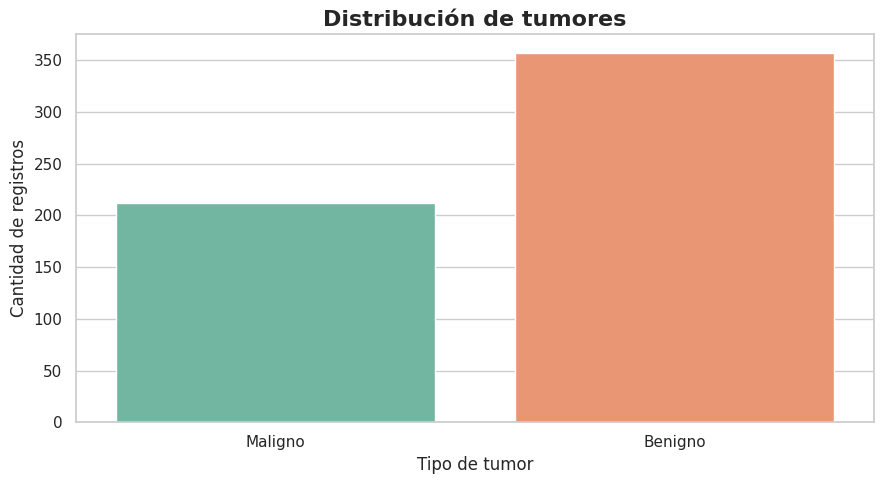

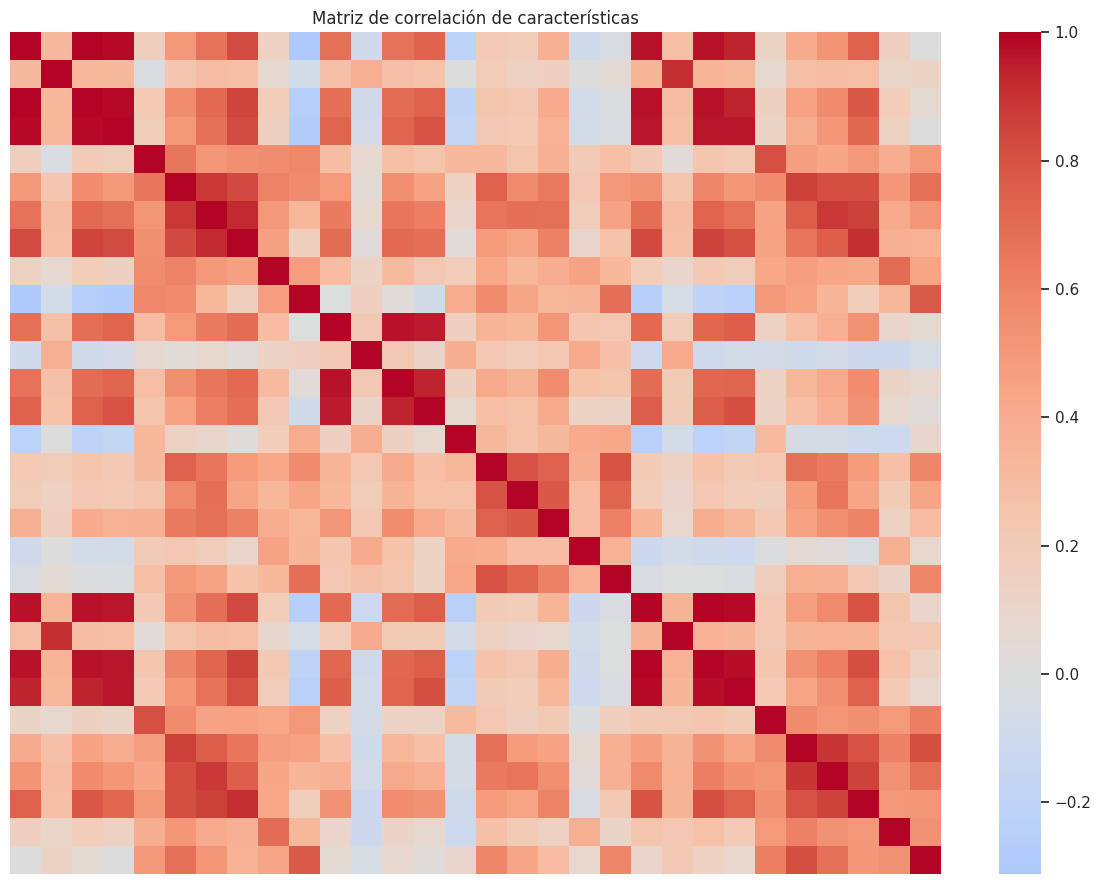

In [2]:
# Distribución de tumores

plt.figure(figsize=(9, 5))

sns.countplot(
    x=pd.Series(y).map({
        0: 'Maligno',
        1: 'Benigno'
    }),
    hue=pd.Series(y).map({
        0: 'Maligno',
        1: 'Benigno'
    }),
    palette='Set2',
    legend=False
)

plt.title(
    'Distribución de tumores',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Tipo de tumor')
plt.ylabel('Cantidad de registros')

plt.tight_layout()
plt.show()


# Correlación entre características

plt.figure(figsize=(12, 9))

sns.heatmap(
    X.corr(),
    cmap='coolwarm',
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title('Matriz de correlación de características')
plt.tight_layout()
plt.show()

In [3]:
# Separar entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Crear modelo Gradient Boosting

gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    min_samples_split=5,
    min_samples_leaf=3,
    subsample=0.9,
    random_state=42
)

# Entrenar modelo

gb_model.fit(X_train, y_train)

print("MODELO ENTRENADO")
print("----------------")
print("Número de árboles:", gb_model.n_estimators)
print("Learning rate:", gb_model.learning_rate)
print("Profundidad máxima:", gb_model.max_depth)
print("Características:", X_train.shape[1])

MODELO ENTRENADO
----------------
Número de árboles: 150
Learning rate: 0.05
Profundidad máxima: 2
Características: 30


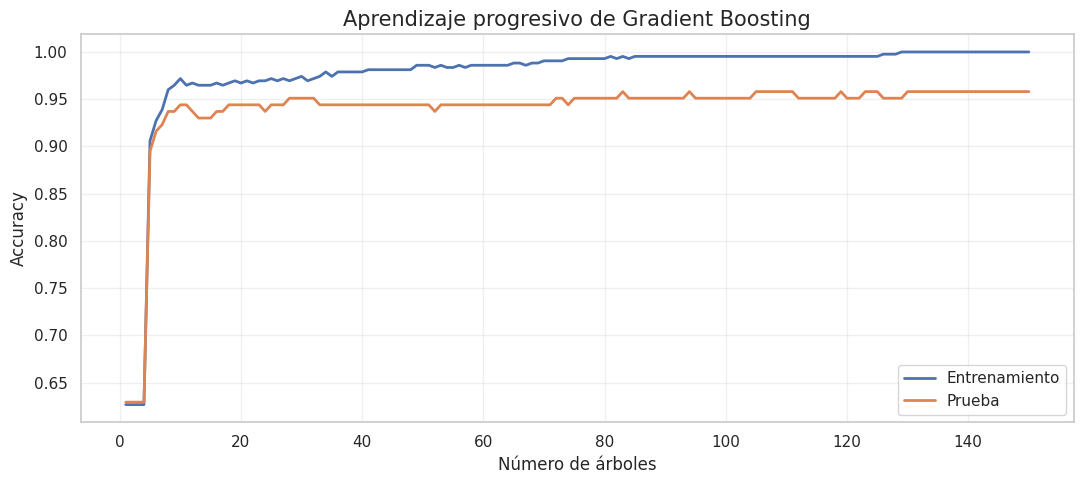

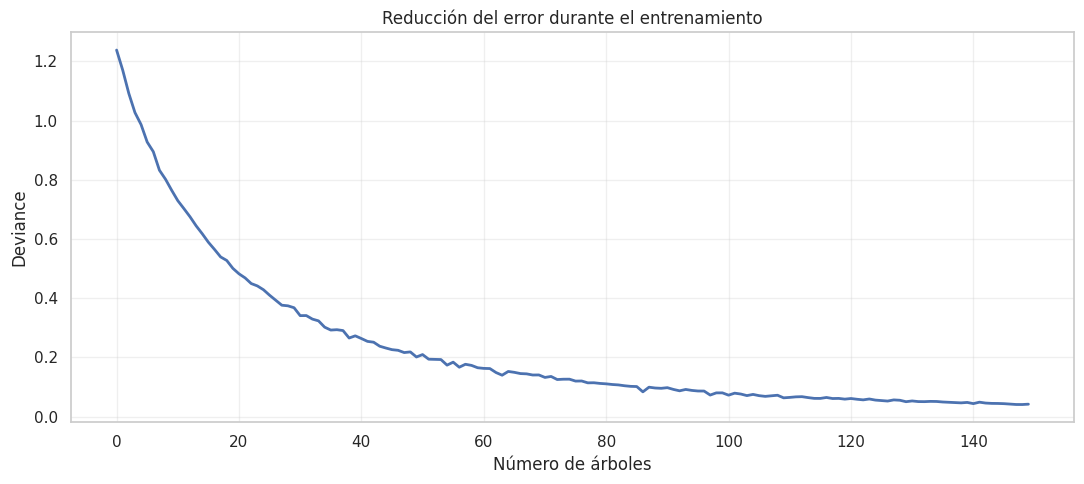

In [4]:
# Obtener precisión progresiva

train_accuracy = []
test_accuracy = []

for pred_train, pred_test in zip(
    gb_model.staged_predict(X_train),
    gb_model.staged_predict(X_test)
):

    train_accuracy.append(
        accuracy_score(y_train, pred_train)
    )

    test_accuracy.append(
        accuracy_score(y_test, pred_test)
    )


plt.figure(figsize=(11, 5))

plt.plot(
    range(1, len(train_accuracy) + 1),
    train_accuracy,
    label='Entrenamiento',
    linewidth=2
)

plt.plot(
    range(1, len(test_accuracy) + 1),
    test_accuracy,
    label='Prueba',
    linewidth=2
)

plt.xlabel('Número de árboles')
plt.ylabel('Accuracy')

plt.title(
    'Aprendizaje progresivo de Gradient Boosting',
    fontsize=15
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Error logístico progresivo

plt.figure(figsize=(11, 5))

plt.plot(
    gb_model.train_score_,
    linewidth=2
)

plt.title('Reducción del error durante el entrenamiento')
plt.xlabel('Número de árboles')
plt.ylabel('Deviance')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

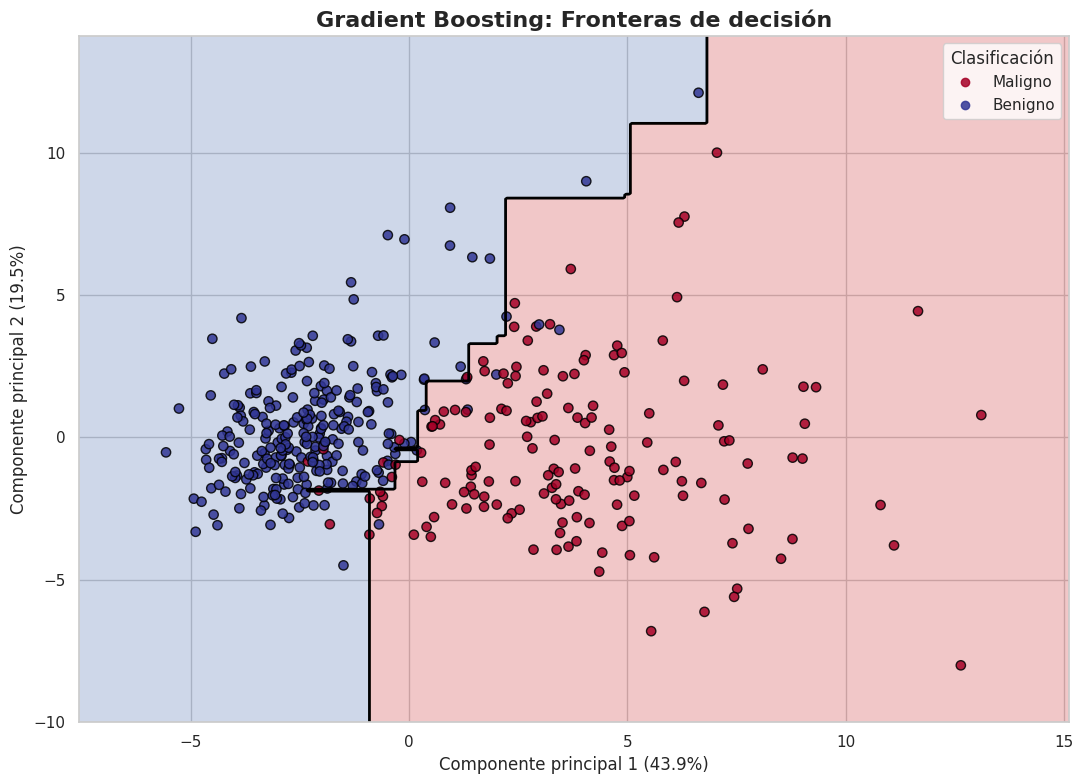

Varianza explicada por PCA: 63.41 %


In [5]:
# ============================================
# FRONTERAS DE DECISIÓN CON PCA
# ============================================

# Estandarizar datos para PCA
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Reducir a dos dimensiones
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Entrenar modelo para visualización
gb_visual = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

gb_visual.fit(X_train_pca, y_train)

# Crear cuadrícula de puntos
x_min, x_max = X_train_pca[:, 0].min() - 2, X_train_pca[:, 0].max() + 2
y_min, y_max = X_train_pca[:, 1].min() - 2, X_train_pca[:, 1].max() + 2

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 350),
    np.linspace(y_min, y_max, 350)
)

# Predecir cada punto de la cuadrícula
Z = gb_visual.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z = Z.reshape(xx.shape)

# Visualización
plt.figure(figsize=(11, 8))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.25,
    cmap='RdYlBu'
)

# Dibujar frontera
plt.contour(
    xx,
    yy,
    Z,
    levels=[0.5],
    colors='black',
    linewidths=2
)

# Mostrar muestras
scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap='RdYlBu',
    edgecolors='black',
    s=45,
    alpha=0.85
)

plt.title(
    'Gradient Boosting: Fronteras de decisión',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel(
    f'Componente principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)'
)

plt.ylabel(
    f'Componente principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)'
)

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=['Maligno', 'Benigno'],
    title='Clasificación'
)

plt.tight_layout()
plt.show()

print(
    "Varianza explicada por PCA:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

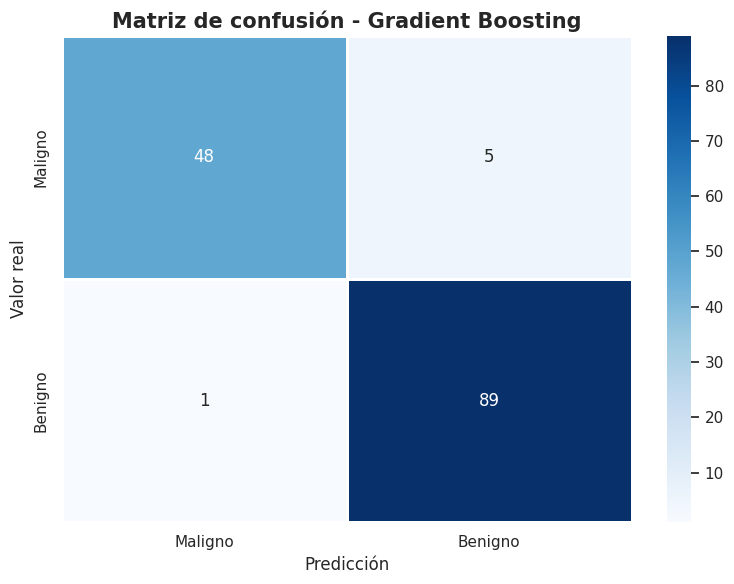


REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     Maligno     0.9796    0.9057    0.9412        53
     Benigno     0.9468    0.9889    0.9674        90

    accuracy                         0.9580       143
   macro avg     0.9632    0.9473    0.9543       143
weighted avg     0.9590    0.9580    0.9577       143



In [6]:
# Predicciones
y_pred = gb_model.predict(X_test)

# Probabilidades
y_prob = gb_model.predict_proba(X_test)[:, 1]

# Matriz de confusión
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    xticklabels=['Maligno', 'Benigno'],
    yticklabels=['Maligno', 'Benigno']
)

plt.title(
    'Matriz de confusión - Gradient Boosting',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Predicción')
plt.ylabel('Valor real')

plt.tight_layout()
plt.show()


# Reporte de clasificación

print("\nREPORTE DE CLASIFICACIÓN")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Maligno', 'Benigno'],
        digits=4
    )
)

RESULTADOS DEL MODELO
Accuracy:  0.9580
Precision: 0.9468
Recall:    0.9889
F1-Score:  0.9674


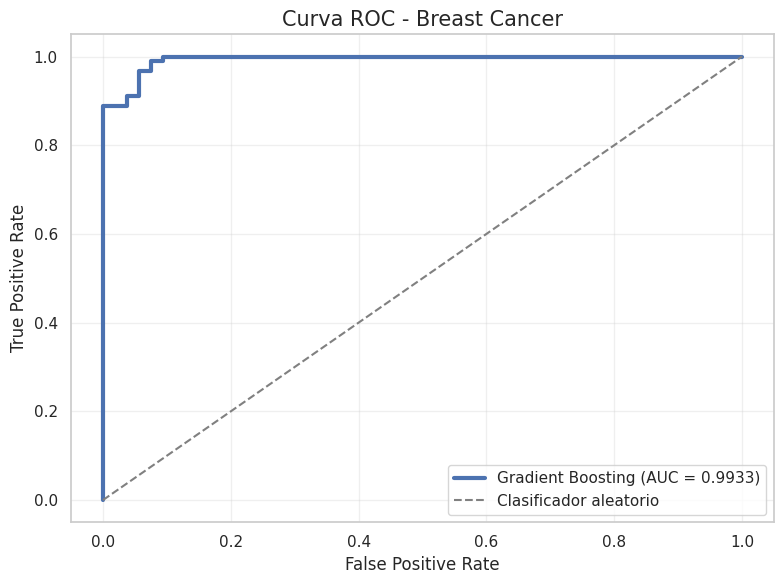

In [7]:
# Métricas generales

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label=1
)

recall = recall_score(
    y_test, y_pred, pos_label=1
)

f1 = f1_score(
    y_test, y_pred, pos_label=1
)

print("RESULTADOS DEL MODELO")
print("=" * 45)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")


# Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=3,
    label=f'Gradient Boosting (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Clasificador aleatorio'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title(
    'Curva ROC - Breast Cancer',
    fontsize=15
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

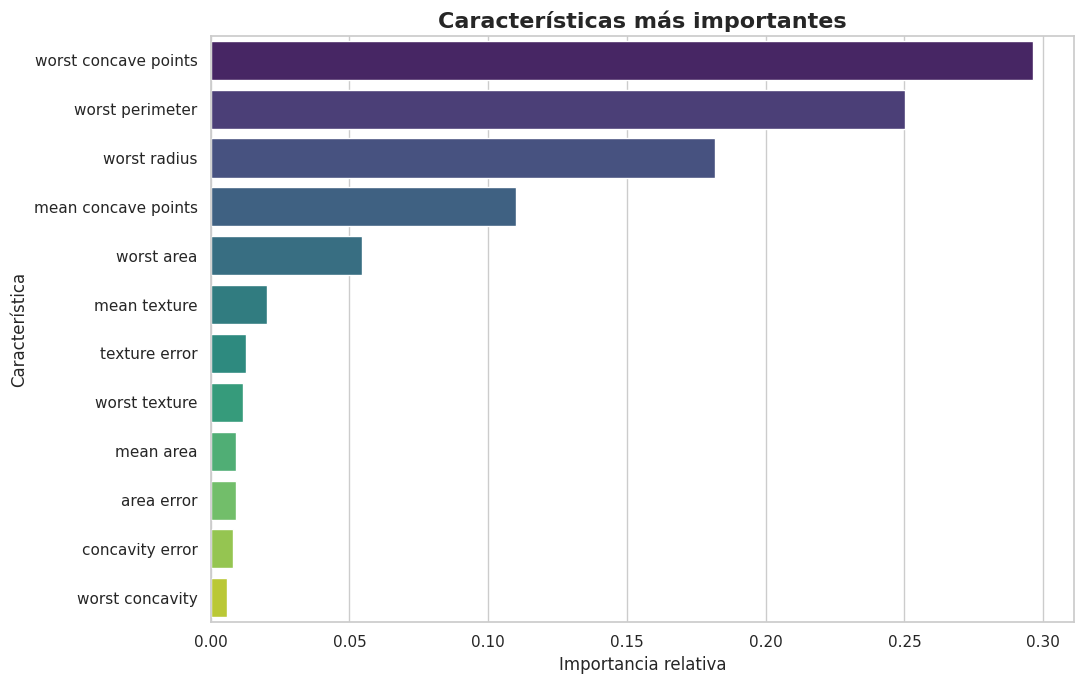

TOP 10 CARACTERÍSTICAS


,Caracteristica,Importancia
27,worst concave points,0.296315
22,worst perimeter,0.250044
20,worst radius,0.181645
7,mean concave points,0.110119
23,worst area,0.054570
1,mean texture,0.020251
11,texture error,0.012689
21,worst texture,0.011686
3,mean area,0.009121
13,area error,0.008927


In [8]:
# Importancia de características

importances = gb_model.feature_importances_

importance_df = pd.DataFrame({
    'Caracteristica': X.columns,
    'Importancia': importances
})

importance_df = importance_df.sort_values(
    by='Importancia',
    ascending=False
)

top_features = importance_df.head(12)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_features,
    x='Importancia',
    y='Caracteristica',
    hue='Caracteristica',
    palette='viridis',
    legend=False
)

plt.title(
    'Características más importantes',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Importancia relativa')
plt.ylabel('Característica')

plt.tight_layout()
plt.show()

print("TOP 10 CARACTERÍSTICAS")
display(importance_df.head(10))

RESULTADO DE CLASIFICACIÓN
Clasificación: BENIGNO
Probabilidad de malignidad: 0.80%
Probabilidad de benignidad: 99.20%

CARACTERÍSTICAS DEL REGISTRO


,519
mean radius,12.75000
mean texture,16.70000
mean perimeter,82.51000
mean area,493.80000
mean smoothness,0.11250
mean compactness,0.11170
mean concavity,0.03880
mean concave points,0.02995
mean symmetry,0.21200
mean fractal dimension,0.06623


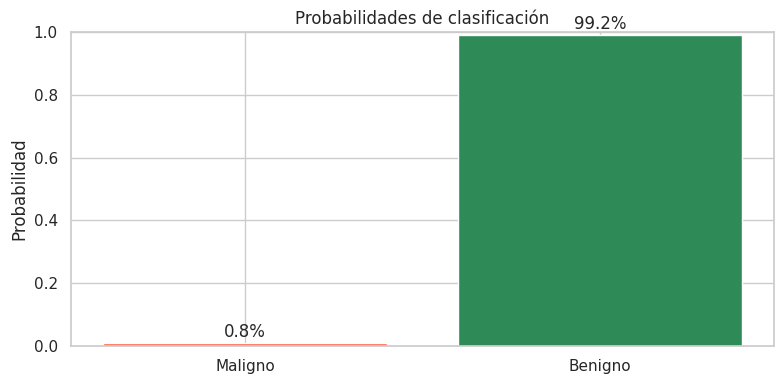

In [9]:
# Seleccionar un paciente de prueba
indice = 0

paciente = X_test.iloc[[indice]]

# Predicción
prediccion = gb_model.predict(paciente)[0]

# Probabilidades
probabilidades = gb_model.predict_proba(paciente)[0]

# Mostrar resultados
nombre_clase = {
    0: 'MALIGNO',
    1: 'BENIGNO'
}

print("=" * 50)
print("RESULTADO DE CLASIFICACIÓN")
print("=" * 50)

print("Clasificación:", nombre_clase[prediccion])

print(
    f"Probabilidad de malignidad: {probabilidades[0]*100:.2f}%"
)

print(
    f"Probabilidad de benignidad: {probabilidades[1]*100:.2f}%"
)

print("\nCARACTERÍSTICAS DEL REGISTRO")
display(paciente.T.head(10))

# Gráfica de probabilidades

plt.figure(figsize=(8, 4))

plt.bar(
    ['Maligno', 'Benigno'],
    probabilidades,
    color=['tomato', 'seagreen']
)

plt.ylim(0, 1)

plt.ylabel('Probabilidad')
plt.title('Probabilidades de clasificación')

for i, valor in enumerate(probabilidades):
    plt.text(
        i,
        valor + 0.02,
        f'{valor*100:.1f}%',
        ha='center'
    )

plt.tight_layout()
plt.show()

,Arboles,Accuracy,F1
0,1,0.629371,0.772532
1,5,0.916084,0.936842
2,10,0.937063,0.951351
3,25,0.937063,0.950276
4,50,0.944056,0.956044
5,75,0.951049,0.961326
6,100,0.944056,0.956044
7,150,0.951049,0.961749


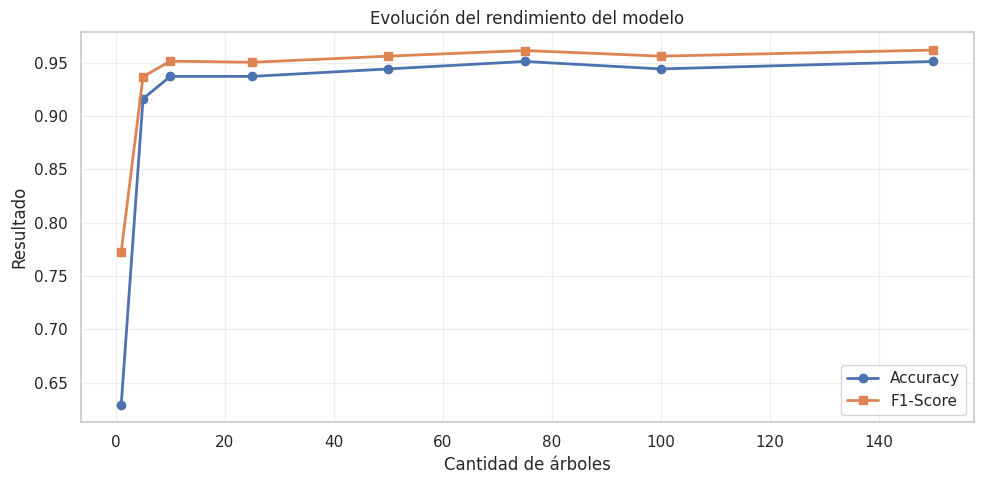

In [10]:
# Comparación de diferentes cantidades de árboles

n_estimators_list = [1, 5, 10, 25, 50, 75, 100, 150]

results = []

for n in n_estimators_list:

    model = GradientBoostingClassifier(
        n_estimators=n,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    results.append({
        'Arboles': n,
        'Accuracy': accuracy_score(y_test, pred),
        'F1': f1_score(y_test, pred)
    })

results_df = pd.DataFrame(results)

display(results_df)

plt.figure(figsize=(10, 5))

plt.plot(
    results_df['Arboles'],
    results_df['Accuracy'],
    marker='o',
    linewidth=2,
    label='Accuracy'
)

plt.plot(
    results_df['Arboles'],
    results_df['F1'],
    marker='s',
    linewidth=2,
    label='F1-Score'
)

plt.xlabel('Cantidad de árboles')
plt.ylabel('Resultado')

plt.title('Evolución del rendimiento del modelo')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()